# RQ2 procedure 3: from profiling traces to a validated, (m,k)-aware CBS budget

The procedure in five steps. One notebook for the three workloads: set `WORKLOAD` in the configuration cell and run top to bottom.

| # | Step | Output |
|---|---|---|
| 1-4 | Load the runs, feasibility ($N\cdot p\ge10$), tail bound $C_p$ of every run, factors $\alpha_{drift}$, $\alpha_{cores}$, $\alpha_{platform}$ | $C_p$ and the margins |
| 5 | **Budgets.** 5.1-5.3: $Q_p$ for each tolerance p (Routes 1, 2, 3). 5.4: the window requirement (m,k), $C_{(m,k)}$ and $Q^*=\max(C_p,C_{(m,k)})\cdot\alpha$ for each level. 5.5: the table to run online | `budgets/budgets_*_p3_iter0.csv` |
| 6 | **Offline validation** on held-out runs (other VMs); if the practitioner wants, recalibrate | pass / fail per route and level |
| 7 | **Online validation**: the runs of `validation_p3/iter<ITER>` judged against their level | verdict per run and per cell |
| 8 | **Recalibration** of the failed cells from the online data (if the practitioner wants) | next budgets file |
| 9 | What to report | |

**Notation.** C = CPU time of a job (`cpu_ns`), W = dispatch wait (`wait_ns`), T = period = deadline, Q = budget, $\delta$ = budget cost of a job beyond its C (`DELTA_MS`).
**Rate requirement:** at most a fraction p of the jobs exceed the budget, $P(C+\delta>Q)\le p$. **Window requirement (m,k):** in any k consecutive jobs at least m meet their deadline; at most a fraction $\varepsilon$ (`EPS_MK`) of the sliding windows may violate it.

In [1]:
from pathlib import Path

# the folder RQ2 of the repository, found from wherever the kernel runs (RQ2, analysis_procedure3 or a folder around them): no paths to edit
RQ2 = next(p for p in [Path.cwd(), *Path.cwd().parents, Path.cwd() / "RQ2"] if (p / "analysis_procedure3").is_dir())

# ======================== EDIT HERE (the only cell to change: pick the workload) ========================
WORKLOAD = "workload4"                        # "workload1" (video decoder), "workload2" (image segmentation), "workload3" (audio processor) or "workload4" (LiDAR preprocessing)

# LEVELS = (name, p, (m, k)): the rate tolerance and the window requirement of each level; k = 1 s of jobs (24 frames, 10 images, 100 audio blocks, 20 scans)
_W = {"workload1": dict(label="video decoder",      ROOT=RQ2,                  DRIFT_DIR=RQ2 / "workload1" / "alpha_drift", VALID_DIR=RQ2 / "workload1" / "validation_p3", PERIOD_MS=41.667,
                  LEVELS=[("relaxed", 1e-2, (22, 24)), ("strict", 1e-3, (23, 24))]),
       "workload2": dict(label="image segmentation", ROOT=RQ2 / "workload2", DRIFT_DIR=RQ2 / "workload2" / "alpha_drift", VALID_DIR=RQ2 / "workload2" / "validation_p3", PERIOD_MS=100.0,
                  LEVELS=[("relaxed", 1e-2, (8, 10)), ("strict", 1e-3, (9, 10))]),
       "workload3": dict(label="audio processor",    ROOT=RQ2 / "workload3", DRIFT_DIR=RQ2 / "workload3" / "alpha_drift", VALID_DIR=RQ2 / "workload3" / "validation_p3", PERIOD_MS=10.0,
                  LEVELS=[("relaxed", 1e-2, (95, 100)), ("strict", 1e-3, (99, 100))]),
       "workload4": dict(label="LiDAR preprocessing", ROOT=RQ2 / "workload4", DRIFT_DIR=RQ2 / "workload4" / "alpha_drift", VALID_DIR=RQ2 / "workload4" / "validation_p4", PERIOD_MS=50.0,
                  LEVELS=[("relaxed", 1e-2, (18, 20)), ("strict", 1e-3, (19, 20))])}[WORKLOAD]
ROOT      = _W["ROOT"]                        # folder with results/ (profiling)
DRIFT_DIR = _W["DRIFT_DIR"]                   # folder with results/<vm>/<scenario>/... of the other VMs of the same type (alpha_drift)
VALID_DIR = _W["VALID_DIR"]                   # online validation: iter<N>/budgets.csv (what was run) and iter<N>/results/
PERIOD_MS = _W["PERIOD_MS"]                   # period = deadline T
LEVELS    = _W["LEVELS"]
SCENARIOS = {"single_core": ["instance0"], "multi_core": ["instance0", "instance1"]}   # scenario -> instances

CONDITIONS = ["baseline1", "cache", "memory", "baseline2"]   # profiling session (folders in ROOT/results/<scenario>/)
BASELINES, STRESS = ["baseline1", "baseline2"], ["cache", "memory"]
DRIFT_VMS = ["worker6", "worker7"]            # other VMs of the same type (DRIFT_DIR/results/<vm>/<scenario>/baseline|cache|memory)

P_LIST = [1e-1, 1e-2, 1e-3]                   # tolerances: admissible P(C > Q)
CONF   = 0.95                                 # confidence of every upper bound
NP_MIN = 10                                   # an empirical bound at p needs N*p >= NP_MIN, otherwise: fall back to Route 3 (HWM)
HWM_P  = 1e-3                                 # p at which Route 3 takes alpha_drift

ALPHA_PLATFORM = {1: 1.03, 2: 1.06, 3: 1.11}  # alpha_platform(m) measured once per VM type with the synthetic victims, m = enemy cores
M_USED = {"single_core": 3, "multi_core": 2}  # m used per scenario
ADMISSION_MAX = 0.95                          # budget Q/T above this is not admitted

DELTA_MS = 0.02                               # budget cost of a job beyond its cpu time (context switch, interrupts), ms: C_p and C_(m,k) are bounds of C + delta
EPS_MK = 0.01                                 # window requirement: allowed share of the sliding windows of k jobs that violate (m,k)
L_BOOT, N_BOOT = 1000, 200                    # moving-block bootstrap: block length (jobs), replicates
GAP_JOBS = 50                                 # overruns closer than this (jobs) count as one cluster
STALL_FRAC = 0.5                              # a job with dispatch wait W above this share of T, and no miss in the 3 jobs before, is a platform stall (not a budget effect)
K_MAX = 2                                     # maximum number of recalibrations

INTERFERENCES = ["none", "memory"]            # online runs per budget: without interference, with the memory enemy
ITER = 0                                      # 0 = first budgets; set to 1 after recalibrating, etc.
OUT_DIR = RQ2 / "analysis_procedure3" / "budgets"   # where the budgets of each iteration are written
BUDGETS_FILE = OUT_DIR / f"budgets_{WORKLOAD}_iter{ITER}.csv"        # section 5: budgets for each tolerance p (routes 1, 2, 3)
P3_FILE      = OUT_DIR / f"budgets_{WORKLOAD}_p3_iter{ITER}.csv"     # section 5.5: budgets of the levels (rate + window), to run online
P3_NEXT      = OUT_DIR / f"budgets_{WORKLOAD}_p3_iter{ITER + 1}.csv" # section 8: recalibrated budgets of the levels
ONLINE_DIR   = VALID_DIR / f"iter{ITER}"                               # online runs of this iteration: budgets.csv and results/<scenario>/<route>/<level>_<none|memory>/instance*.csv

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, beta

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.3f}".format)
ALPHA = 1 - CONF

def read_run(path):
    """one CSV: warm-up jobs removed, in job order"""
    df = pd.read_csv(path, usecols=["job_id", "cpu_ns", "response_ns", "wait_ns", "deadline_met", "skipped", "warmup"])
    return df[df.warmup == 0].sort_values("job_id").reset_index(drop=True)

def cp_upper(k, n):
    """Clopper-Pearson one-sided upper bound of a probability seen k times in n trials"""
    return 1.0 if k >= n else float(beta.ppf(1 - ALPHA, k + 1, n - k))

def os_ucb(xs, p):
    """order-statistic upper bound of the (1-p) quantile: x_(j), j = smallest rank with Binom(N, 1-p).cdf(j-1) >= CONF. NaN if j > N (N*p too small)"""
    n = len(xs)
    j = int(binom.ppf(CONF, n, 1 - p)) + 1
    return xs[j - 1] if j <= n else np.nan

def boot_ucb(x, ps):
    """moving-block bootstrap upper bound of the (1-p) quantile (keeps the clustering of the jobs)"""
    n = len(x); nb = n // L_BOOT
    if nb < 2:
        return np.full(len(ps), np.nan)
    rng = np.random.default_rng(0); q = np.empty((N_BOOT, len(ps)))
    for b in range(N_BOOT):
        starts = rng.integers(0, n - L_BOOT + 1, nb)
        q[b] = np.quantile(x[(starts[:, None] + np.arange(L_BOOT)).ravel()], [1 - p for p in ps])
    return np.quantile(q, CONF, axis=0)

def bound_table(x, ps):
    """C_p of a series x (ms): point estimate, the two upper bounds, and ucb = the larger one (NaN if N*p < NP_MIN)"""
    xs = np.sort(x)
    os_ = np.array([os_ucb(xs, p) for p in ps]); bt = boot_ucb(x, ps)
    ok = np.array([len(x) * p >= NP_MIN for p in ps])
    ucb = np.where(ok & ~np.isnan(os_), np.fmax(os_, bt), np.nan)
    return pd.DataFrame(dict(p=ps, point=np.quantile(x, [1 - p for p in ps]), orderstat=os_, block_boot=bt, ucb=ucb)).set_index("p")

def exceed_test(x, Q, p):
    """overruns C + delta > Q: rate, number of clusters, upper bound of P(C+delta>Q) = CP upper bound of clusters/N times the mean cluster size, and ucb <= p"""
    if np.isnan(Q):
        return np.nan, 0, np.nan, False
    x = x + DELTA_MS
    idx = np.flatnonzero(x > Q); n = len(x)
    if len(idx) == 0:
        return 0.0, 0, cp_upper(0, n), cp_upper(0, n) <= p
    ncl = 1 + int(np.sum(np.diff(idx) > GAP_JOBS))
    ucb = cp_upper(ncl, n) * len(idx) / ncl
    return len(idx) / n, ncl, ucb, ucb <= p

# ---- window requirement (m,k): at least m of any k consecutive jobs meet their deadline ----
def window_counts(x, k):
    """number of True in every sliding window of k consecutive jobs"""
    cs = np.r_[0, np.cumsum(x.astype(int))]
    return cs[k:] - cs[:-k]

def violation_fraction(miss, m, k):
    """share of the sliding windows of k jobs with more than k-m misses (fewer than m deadlines met); miss = missed jobs (late or skipped), in job order"""
    return float((window_counts(miss, k) > k - m).mean()) if len(miss) >= k else np.nan

def window_share(c, Q, m, k):
    """the same from the C of the jobs: one overrun (C + delta > Q) costs about two misses (the late job and the skipped release), so a window tolerates j = (k-m)//2 overruns"""
    return float((window_counts(c + DELTA_MS > Q, k) > (k - m) // 2).mean()) if len(c) >= k else np.nan

def count_budget(c, m, k, eps, grid=300):
    """C_(m,k): smallest level (ms) such that at most eps of the windows of k jobs hold more than j = (k-m)//2 jobs with C + delta > level. Jobs with C > 2T are stalls, not part of it"""
    c = c[c <= 2 * PERIOD_MS]
    qs = np.geomspace(np.median(c), c.max(), grid)
    lo, hi = 0, grid - 1                                           # the maximum is always enough: no overrun
    while lo < hi:
        mid = (lo + hi) // 2
        if window_share(c, qs[mid], m, k) <= eps:
            hi = mid
        else:
            lo = mid + 1
    return float(qs[lo])

def overrun_misses(bad, over):
    """misses (late or skipped jobs) that belong to a burst of consecutive misses containing an overrun: caused by an overrun, with its skip effect.
    The other misses (a burst without any overrun: stalls, late starts) are not controlled by the budget."""
    edges = np.diff(np.r_[0, bad.astype(int), 0])
    out = np.zeros(len(bad), bool)
    for s, e in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        if over[s:e].any():
            out[s:e] = True
    return out

def stall_count(w, bad):
    """platform stalls of a run: jobs with W (ms) above STALL_FRAC*T while none of the 3 jobs before was missed (otherwise it is the throttling after an overrun)"""
    s = (np.nan_to_num(w, nan=0.0) > STALL_FRAC * PERIOD_MS) & (np.convolve(bad.astype(int), [0, 1, 1, 1])[:len(bad)] == 0)
    return int((np.diff(np.r_[0, s.astype(int)]) == 1).sum())

## 1. Load the runs and simple statistics

Runs: the **profiling session** (`baseline1 → cache → memory → baseline2`, in `ROOT/results/`) and the runs on **other VMs** of the same type (`DRIFT_DIR/results/<vm>/`, the swapped session).
Skipped jobs have no C, R or W and are left out of the statistics. Warm-up jobs are always removed.

In [4]:
runs = []
for scen in SCENARIOS:
    for cond in CONDITIONS:
        runs.append(dict(run=f"profiling_{cond}", group="profiling", vm="profiling", scen=scen, cond=cond,
                         kind="base" if cond in BASELINES else "stress", dir=ROOT / "results" / scen / cond))
    for vm in DRIFT_VMS:
        for cond, kind in [("baseline", "base")] + [(c, "stress") for c in STRESS]:
            runs.append(dict(run=f"drift_{vm}_{cond}", group="drift", vm=vm, scen=scen, cond=cond, kind=kind,
                             dir=DRIFT_DIR / "results" / vm / scen / cond))
runs = [r for r in runs if (r["dir"] / "instance0.csv").exists()]
print("working folder :", Path.cwd())
print("ROOT             :", ROOT.resolve(), "| exists:", (ROOT / "results").exists(), "(needs ROOT/results)")
print("DRIFT_DIR        :", DRIFT_DIR.resolve(), "| exists:", (DRIFT_DIR / "results").exists(), "(needs DRIFT_DIR/results)")
print("runs found       :", len(runs), "| profiling:", sum(r["group"] == "profiling" for r in runs), "| other VMs:", sum(r["group"] == "drift" for r in runs))
if not any(r["group"] == "profiling" for r in runs):
    raise FileNotFoundError(f"no profiling runs: looked for {ROOT.resolve() / 'results' / 'single_core' / 'baseline1' / 'instance0.csv'}. The paths in the configuration cell are relative to the working folder printed above: "
                            f"check that ROOT/results holds the profiling runs (ROOT is chosen from WORKLOAD in the configuration cell).")

data, series, wseries = {}, {}, {}                        # data: all jobs of a run; series: C (ms) of the non-skipped jobs, in job order
for r in runs:
    for inst in SCENARIOS[r["scen"]]:
        f = r["dir"] / f"{inst}.csv"
        if f.exists():
            key = (r["run"], r["scen"], inst)
            data[key] = read_run(f)
            d = data[key]; series[key] = (d[d.skipped == 0].cpu_ns / 1e6).to_numpy(); wseries[key] = (d[d.skipped == 0].wait_ns / 1e6).to_numpy()

inv = pd.DataFrame([dict(run=k[0], scenario=k[1], instance=k[2], jobs=len(data[k]), skipped=int((data[k].skipped == 1).sum()),
                         late=int(((data[k].skipped == 0) & (data[k].deadline_met == 0)).sum())) for k in data])
display(inv.set_index(["scenario", "run", "instance"]))

working folder : /home/silvia/Documents/GraduationProject/research-questions/RQ2
ROOT             : /home/silvia/Documents/GraduationProject/research-questions/RQ2/workload4 | exists: True (needs ROOT/results)
DRIFT_DIR        : /home/silvia/Documents/GraduationProject/research-questions/RQ2/workload4/alpha_drift | exists: True (needs DRIFT_DIR/results)
runs found       : 14 | profiling: 8 | other VMs: 6


jobs  skipped  late
scenario    run                    instance                       
single_core profiling_baseline1    instance0  50000        0     0
            profiling_cache        instance0  50000        0     0
            profiling_memory       instance0  50000        0     0
            profiling_baseline2    instance0  50000        0     0
            drift_worker7_baseline instance0  30000        0     0
            drift_worker7_cache    instance0  30000        0     0
            drift_worker7_memory   instance0  30000        0     0
multi_core  profiling_baseline1    instance0  50000        3     3
                                   instance1  50000        3     3
            profiling_cache        instance0  50000        2     2
                                   instance1  50000        2     2
            profiling_memory       instance0  50000        1     1
                                   instance1  50000        1     1
            profiling_baseline2    instance0  50000        0     0
                                   instance1  50000        0     0
            drift_worker6_baseline instance0  30000        0     0
                                   instance1  30000        0     0
            drift_worker6_cache    instance0  30000        0     0
                                   instance1  30000        0     0
            drift_worker6_memory   instance0  30000        0     0
                                   instance1  30000        0     0

### 1.1 Distribution of C, R and W in the profiling session (ms)
`cv` = std / mean. The stressed runs show how much the tail moves; baseline1 and baseline2 show the drift inside one VM.

In [5]:
def describe(v):
    q = np.quantile(v, [.5, .9, .99, .999])
    return dict(n=len(v), mean=v.mean(), cv=v.std() / v.mean(), p50=q[0], p90=q[1], p99=q[2], p999=q[3], max=v.max())

COLS = dict(C="cpu_ns", R="response_ns", W="wait_ns")
rows = []
for r in runs:
    if r["group"] != "profiling":
        continue
    for inst in SCENARIOS[r["scen"]]:
        d = data[(r["run"], r["scen"], inst)]; d = d[d.skipped == 0]
        for name, col in COLS.items():
            rows.append(dict(scenario=r["scen"], instance=inst, condition=r["cond"], quantity=name, **describe(d[col] / 1e6)))
stats = pd.DataFrame(rows)
for name in COLS:
    print(f"--- {name} ---")
    display(stats[stats.quantity == name].drop(columns="quantity").set_index(["scenario", "instance", "condition"]))

--- C ---


n   mean    cv    p50    p90    p99   p999    max
scenario    instance  condition                                                       
single_core instance0 baseline1  50000 21.978 0.118 22.240 25.141 26.861 27.715 31.223
                      cache      50000 22.582 0.115 22.876 25.738 27.440 28.258 33.041
                      memory     50000 22.405 0.116 22.724 25.559 27.265 28.248 41.203
                      baseline2  50000 21.746 0.118 22.009 24.884 26.528 27.291 27.932
multi_core  instance0 baseline1  49997 21.231 0.124 21.481 24.374 26.020 26.840 31.315
            instance1 baseline1  49997 21.233 0.124 21.482 24.381 26.015 26.843 31.196
            instance0 cache      49998 21.907 0.117 22.190 24.996 26.732 27.565 31.725
            instance1 cache      49998 21.908 0.117 22.187 25.008 26.734 27.524 31.706
            instance0 memory     49999 21.358 0.123 21.617 24.493 26.174 27.071 29.476
            instance1 memory     49999 21.367 0.123 21.623 24.511 26.176 27.113 29.954
            instance0 baseline2  50000 20.173 0.150 20.961 23.525 25.184 26.152 27.478
            instance1 baseline2  50000 20.177 0.150 20.959 23.530 25.178 26.153 26.609

--- R ---


n   mean    cv    p50    p90    p99   p999    max
scenario    instance  condition                                                       
single_core instance0 baseline1  50000 22.167 0.116 22.445 25.286 26.988 27.889 31.335
                      cache      50000 22.765 0.112 23.082 25.847 27.526 28.327 33.355
                      memory     50000 22.591 0.114 22.929 25.681 27.394 28.345 46.429
                      baseline2  50000 21.935 0.117 22.206 25.055 26.687 27.430 28.017
multi_core  instance0 baseline1  49997 21.412 0.123 21.664 24.527 26.177 27.074 66.262
            instance1 baseline1  49997 21.432 0.124 21.687 24.565 26.192 27.139 66.232
            instance0 cache      49998 22.092 0.115 22.388 25.132 26.859 27.748 63.166
            instance1 cache      49998 22.105 0.116 22.399 25.159 26.868 27.744 63.133
            instance0 memory     49999 21.539 0.121 21.805 24.649 26.318 27.290 51.745
            instance1 memory     49999 21.566 0.122 21.832 24.689 26.360 27.355 51.823
            instance0 baseline2  50000 20.357 0.148 21.146 23.692 25.354 26.370 38.051
            instance1 baseline2  50000 20.369 0.148 21.156 23.703 25.373 26.344 38.076

--- W ---


n  mean    cv   p50   p90   p99  p999    max
scenario    instance  condition                                                  
single_core instance0 baseline1  50000 0.169 0.552 0.187 0.216 0.263 0.308  6.494
                      cache      50000 0.161 0.536 0.197 0.240 0.278 0.333  2.721
                      memory     50000 0.165 0.845 0.192 0.231 0.272 0.323 22.960
                      baseline2  50000 0.170 0.464 0.181 0.202 0.250 0.287  5.116
multi_core  instance0 baseline1  49997 0.170 2.175 0.162 0.226 0.243 0.295 42.574
            instance1 baseline1  49997 0.188 1.973 0.205 0.230 0.245 0.302 42.571
            instance0 cache      49998 0.170 1.618 0.177 0.239 0.260 0.323 40.264
            instance1 cache      49998 0.182 1.509 0.201 0.243 0.264 0.327 40.269
            instance0 memory     49999 0.169 0.907 0.166 0.227 0.244 0.288 27.260
            instance1 memory     49999 0.188 0.830 0.216 0.236 0.252 0.312 27.412
            instance0 baseline2  50000 0.174 0.589 0.164 0.221 0.235 0.280 17.328
            instance1 baseline2  50000 0.183 0.557 0.193 0.224 0.236 0.276 17.390

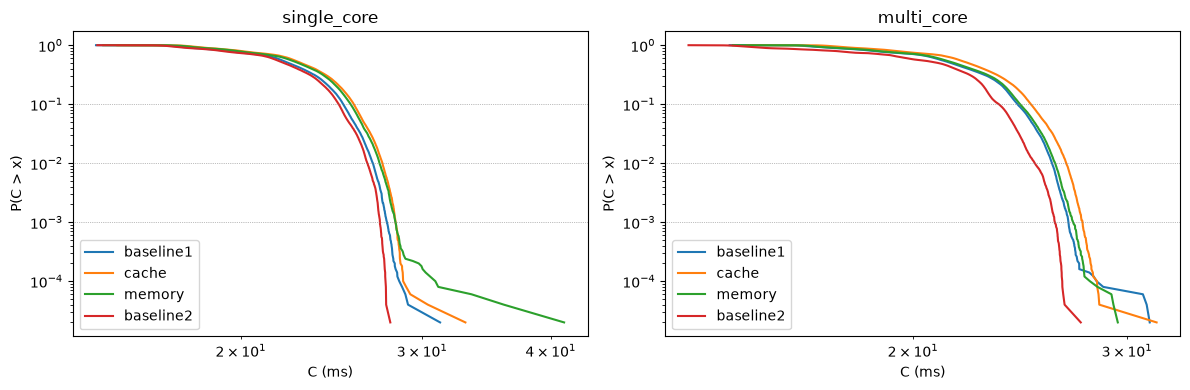

In [6]:
# survival function P(C > x) of instance0: the right end is the tail the budget has to cover
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(6 * len(SCENARIOS), 4), squeeze=False)
for ax, scen in zip(axes[0], SCENARIOS):
    for r in runs:
        key = (r["run"], scen, "instance0")
        if r["group"] == "profiling" and r["scen"] == scen:
            x = np.sort(series[key]); ax.loglog(x, 1 - np.arange(1, len(x) + 1) / len(x) + 1 / len(x), label=r["cond"])
    for p in P_LIST:
        ax.axhline(p, color="grey", lw=.5, ls=":")
    ax.set_title(scen); ax.set_xlabel("C (ms)"); ax.set_ylabel("P(C > x)"); ax.legend()
plt.tight_layout(); plt.show()

## 2. Feasibility: is $N\cdot p \ge 10$?

The empirical bound of the $(1-p)$ quantile needs enough jobs above it. With N jobs the expected number of jobs beyond the quantile is $N\cdot p$; we ask for $N\cdot p \ge 10$ (the order-statistic bound at 95% needs $N \gtrsim 3/p$ at the very least).
For a tolerance that does not meet it, the empirical Routes 1 and 2 are **not available** and the budget falls back to **Route 3 (high-water mark)**, or more data has to be collected.
EVT is not part of the procedure: a practitioner who wants it has to check its fit separately.

In [7]:
rows = [dict(scenario=k[1], run=k[0], instance=k[2], N=len(series[k]), **{f"N*p (p={p:g})": len(series[k]) * p for p in P_LIST}) for k in series]
feas = pd.DataFrame(rows)
display(feas.set_index(["scenario", "run", "instance"]))

feasible = {(scen, p): all(len(series[k]) * p >= NP_MIN for k in series if k[1] == scen) for scen in SCENARIOS for p in P_LIST}
print(pd.Series(feasible).unstack().rename_axis(index="scenario", columns="p").to_string())
print("\nFalse = N*p < %d in at least one run: Routes 1 and 2 fall back to Route 3 for that p." % NP_MIN)

N  N*p (p=0.1)  N*p (p=0.01)  N*p (p=0.001)
scenario    run                    instance                                                  
single_core profiling_baseline1    instance0  50000     5000.000       500.000         50.000
            profiling_cache        instance0  50000     5000.000       500.000         50.000
            profiling_memory       instance0  50000     5000.000       500.000         50.000
            profiling_baseline2    instance0  50000     5000.000       500.000         50.000
            drift_worker7_baseline instance0  30000     3000.000       300.000         30.000
            drift_worker7_cache    instance0  30000     3000.000       300.000         30.000
            drift_worker7_memory   instance0  30000     3000.000       300.000         30.000
multi_core  profiling_baseline1    instance0  49997     4999.700       499.970         49.997
                                   instance1  49997     4999.700       499.970         49.997
            profiling_cache        instance0  49998     4999.800       499.980         49.998
                                   instance1  49998     4999.800       499.980         49.998
            profiling_memory       instance0  49999     4999.900       499.990         49.999
                                   instance1  49999     4999.900       499.990         49.999
            profiling_baseline2    instance0  50000     5000.000       500.000         50.000
                                   instance1  50000     5000.000       500.000         50.000
            drift_worker6_baseline instance0  30000     3000.000       300.000         30.000
                                   instance1  30000     3000.000       300.000         30.000
            drift_worker6_cache    instance0  30000     3000.000       300.000         30.000
                                   instance1  30000     3000.000       300.000         30.000
            drift_worker6_memory   instance0  30000     3000.000       300.000         30.000
                                   instance1  30000     3000.000       300.000         30.000

p            0.001  0.010  0.100
scenario                        
multi_core    True   True   True
single_core   True   True   True

False = N*p < 10 in at least one run: Routes 1 and 2 fall back to Route 3 for that p.


## 3. Tail bound $C_p$ of every run

For a run with N job times $x_1,\dots,x_N$ and tolerance p, $C_p$ is the $(1-p)$ quantile, bounded from above with confidence `CONF`:

- **order statistic:** the number of jobs below the true quantile follows $\mathrm{Binomial}(N, 1-p)$, so the sorted sample element $x_{(j)}$ with $j=\min\{j: F_{Bin}(j-1)\ge CONF\}$ is an upper bound. Valid for independent jobs.
- **moving-block bootstrap:** resample blocks of `L_BOOT` consecutive jobs and take the `CONF` quantile of the bootstrap quantiles. Keeps the clustering of slow jobs.
- **$C_p$ = the larger of the two** (`ucb`). NaN when $N\cdot p < $ `NP_MIN`.

The next cells use `ucb` only.

In [8]:
bnd = {k: bound_table(series[k] + DELTA_MS, P_LIST) for k in series}          # C_p of C + delta
rows = [dict(scenario=k[1], instance=k[2], run=k[0], p=p, **bnd[k].loc[p].to_dict()) for k in bnd for p in P_LIST]
bt = pd.DataFrame(rows)
display(bt.pivot_table(index=["scenario", "instance", "run"], columns="p", values="ucb", sort=False))

p                                             0.100  0.010  0.001
scenario    instance  run                                        
single_core instance0 profiling_baseline1    25.196 26.929 27.833
                      profiling_cache        25.784 27.492 28.357
                      profiling_memory       25.636 27.351 28.370
                      profiling_baseline2    24.925 26.591 27.358
                      drift_worker7_baseline 23.966 25.503 26.224
                      drift_worker7_cache    24.744 26.369 27.229
                      drift_worker7_memory   24.092 25.667 26.405
multi_core  instance0 profiling_baseline1    24.425 26.086 26.909
                      profiling_cache        25.078 26.818 27.627
                      profiling_memory       24.557 26.234 27.253
                      profiling_baseline2    23.576 25.262 26.280
                      drift_worker6_baseline 25.093 26.769 27.787
                      drift_worker6_cache    25.327 27.190 31.004
                      drift_worker6_memory   25.054 26.741 27.582
            instance1 profiling_baseline1    24.436 26.083 26.924
                      profiling_cache        25.081 26.822 27.632
                      profiling_memory       24.581 26.244 27.331
                      profiling_baseline2    23.580 25.259 26.235
                      drift_worker6_baseline 25.021 26.667 27.728
                      drift_worker6_cache    25.268 27.113 30.901
                      drift_worker6_memory   25.008 26.704 27.513

## 4. Factors

### 4.1 $\alpha_{drift}$: variation of the bound between runs and VMs
Every baseline run of a scenario (the two profiling baselines and the baselines on the other VMs) gets its own $C_p$. With $C_p(r)$ the bound of run r:

$$\alpha_{drift}(p) = \frac{\max_r C_p(r)}{\min_r C_p(r)}$$

per instance; the deployment value is the worst instance. With n runs, a new run is covered with probability about $n/(n+1)$ (exchangeable runs), so n is reported: **few runs mean a weak guarantee**.
An episode inside one baseline is not removed: it enters the spread, which is what the factor is for.

In [9]:
rows = []
for scen, insts in SCENARIOS.items():
    names = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]
    for inst in insts:
        for p in P_LIST:
            v = np.array([bnd[(n, scen, inst)].loc[p, "ucb"] for n in names if (n, scen, inst) in bnd])
            rows.append(dict(scenario=scen, instance=inst, p=p, n_runs=len(v), alpha=v.max() / v.min()))
spread = pd.DataFrame(rows)
alpha_drift = spread.groupby(["scenario", "p"]).agg(alpha=("alpha", "max"), n_runs=("n_runs", "min"))
alpha_drift["coverage n/(n+1)"] = alpha_drift.n_runs / (alpha_drift.n_runs + 1)
display(alpha_drift)

alpha  n_runs  coverage n/(n+1)
scenario    p                                     
multi_core  0.001  1.057       3             0.750
            0.010  1.060       3             0.750
            0.100  1.064       3             0.750
single_core 0.001  1.061       3             0.750
            0.010  1.056       3             0.750
            0.100  1.051       3             0.750

### 4.2 $\alpha_{cores}$ (stress) and $\alpha_{platform}$
- $\alpha_{cores}(p) = C_p^{stress} / C_p^{base}$ measured on the profiling VM, one value per stressor. It tells how much the stress moves the tail (reported; Route 1 already contains it).
- $\alpha_{platform}(m)$ is the factor of the synthetic victims (measured once per VM type, `ALPHA_PLATFORM`, m = number of enemy cores). Route 2 uses it in place of the stress profiling of the task.

In [10]:
def prof_runs(scen, kind):
    return [r["run"] for r in runs if r["scen"] == scen and r["group"] == "profiling" and r["kind"] == kind]

rows = []
for scen, insts in SCENARIOS.items():
    for inst in insts:
        for p in P_LIST:
            base = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "base")])
            for n in prof_runs(scen, "stress"):
                rows.append(dict(scenario=scen, instance=inst, p=p, stress=n.replace("profiling_", ""), alpha_cores=bnd[(n, scen, inst)].loc[p, "ucb"] / base))
ac = pd.DataFrame(rows)
display(ac.groupby(["scenario", "stress", "p"]).alpha_cores.max().unstack("p"))
print("alpha_platform used:", {s: (M_USED[s], ALPHA_PLATFORM[M_USED[s]]) for s in SCENARIOS}, "(scenario: (m, factor))")

p                   0.001  0.010  0.100
scenario    stress                     
multi_core  cache   1.027  1.028  1.027
            memory  1.015  1.006  1.006
single_core cache   1.019  1.021  1.023
            memory  1.019  1.016  1.017

alpha_platform used: {'single_core': (3, 1.11), 'multi_core': (2, 1.06)} (scenario: (m, factor))


## 5. Budgets

$C_p^{base}$ = largest bound of the two profiling baselines, $C_p^{stress}$ = largest bound over the stressed runs (cache, memory), per instance. One reservation serves all instances of a scenario, so the deployment budget $Q^*$ is the **maximum over the instances**.

| Route | Formula | Needs |
|---|---|---|
| 1 (full profiling) | $Q = C_p^{stress}\cdot\alpha_{drift}(p)$ | stress profiling of the task |
| 2 (baseline + platform factor) | $Q = C_p^{base}\cdot\alpha_{platform}(m)\cdot\alpha_{drift}(p)$ | baseline profiling only |
| 3 (high-water mark) | $Q = \max C^{stress}\cdot\alpha_{drift}(HWM_P)$, **one value for every p** | stress profiling; no tail estimate. Jobs with $C>2T$ (stalls) are left out of the maximum |

Rules applied after the formulas: (i) where $N\cdot p<10$ Route 1 and 2 are replaced by Route 3 (marked `*`); (ii) **monotone in p**: a stricter tolerance never gets a smaller budget than a looser one; (iii) admission: $Q/T \le$ `ADMISSION_MAX` for Routes 1 and 2, while **Route 3 is capped at `ADMISSION_MAX` $\cdot T$** (a high-water mark above that is useless): the cap is flagged `(capped)` and the share of stressed jobs left above it is printed.

In [11]:
def hwm_ms(scen, inst):
    return max(series[(n, scen, inst)][series[(n, scen, inst)] <= 2 * PERIOD_MS].max() + DELTA_MS for n in prof_runs(scen, "stress"))

def finalize(raw):
    """raw: scenario, route, p, Q_raw (ms) -> fallback to Route 3 where NaN, monotone envelope in p, Q/T, admission"""
    out = []
    for (scen, route), g in raw.groupby(["scenario", "route"], sort=False):
        g = g.sort_values("p", ascending=False).copy()                    # loosest tolerance first
        h = raw[(raw.scenario == scen) & (raw.route == "hwm")].Q_raw.iloc[0]
        g["fallback"] = g.Q_raw.isna() & (route != "hwm")
        g["Q_ms"] = g.Q_raw.fillna(h).cummax()                           # a stricter p is never cheaper
        out.append(g)
    out = pd.concat(out)
    out["Q_over_T"] = out.Q_ms / PERIOD_MS
    out["admitted"] = out.Q_over_T <= ADMISSION_MAX
    return out.reset_index(drop=True)

rows = []
for scen, insts in SCENARIOS.items():
    a_h = alpha_drift.loc[(scen, HWM_P), "alpha"]; a_h = 1.0 if np.isnan(a_h) else a_h
    q3_raw = max(hwm_ms(scen, i) for i in insts) * a_h
    q3 = min(q3_raw, ADMISSION_MAX * PERIOD_MS)                  # Route 3 is only useful if admissible: cap it at the largest admissible budget
    for p in P_LIST:
        a = alpha_drift.loc[(scen, p), "alpha"]
        q1, q2 = [], []
        for inst in insts:
            base = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "base")])
            stress = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "stress")])
            q1.append(stress * a); q2.append(base * ALPHA_PLATFORM[M_USED[scen]] * a)
        rows += [dict(scenario=scen, route="route1", p=p, Q_raw=np.max(q1)), dict(scenario=scen, route="route2b", p=p, Q_raw=np.max(q2)),
                 dict(scenario=scen, route="hwm", p=p, Q_raw=q3, hwm_capped=bool(q3_raw > q3))]
raw = pd.DataFrame(rows)
raw["hwm_capped"] = raw.hwm_capped.fillna(False).astype(bool)
bud = finalize(raw)

show = bud.assign(cell=lambda x: x.Q_ms.round(3).astype(str) + " (" + x.Q_over_T.round(3).astype(str) + ")" + np.where(x.fallback, "*", "") + np.where(x.hwm_capped, " (capped)", "") + np.where(x.admitted, "", " NOT ADMITTED"))
display(show.pivot_table(index=["scenario", "route"], columns="p", values="cell", aggfunc="first"))
print("cell = Q* in ms (Q*/T);  * = fallback to Route 3 because N*p < %d;  (capped) = Route 3 cut at ADMISSION_MAX * T" % NP_MIN)
for scen in SCENARIOS:                                                            # a capped Route 3 is not a high-water mark any more: show what it leaves uncovered
    g = bud[(bud.scenario == scen) & (bud.route == "hwm") & bud.hwm_capped]
    if len(g):
        c = np.concatenate([series[(n, scen, i)] for n in prof_runs(scen, "stress") for i in SCENARIOS[scen]])
        print(f"{scen}: Route 3 capped at {g.Q_ms.iloc[0]:.2f} ms; {np.mean(c + DELTA_MS > g.Q_ms.iloc[0]):.2e} of the stressed-run jobs are still above it")

p                             0.001           0.010           0.100
scenario    route                                                  
multi_core  hwm      33.564 (0.671)  33.564 (0.671)  33.564 (0.671)
            route1   29.216 (0.584)  28.422 (0.568)  26.695 (0.534)
            route2b  30.175 (0.604)  29.301 (0.586)  27.568 (0.551)
single_core hwm      43.753 (0.875)  43.753 (0.875)  43.753 (0.875)
            route1   30.111 (0.602)  29.029 (0.581)  27.107 (0.542)
            route2b  32.792 (0.656)  31.562 (0.631)  29.402 (0.588)

cell = Q* in ms (Q*/T);  * = fallback to Route 3 because N*p < 10;  (capped) = Route 3 cut at ADMISSION_MAX * T


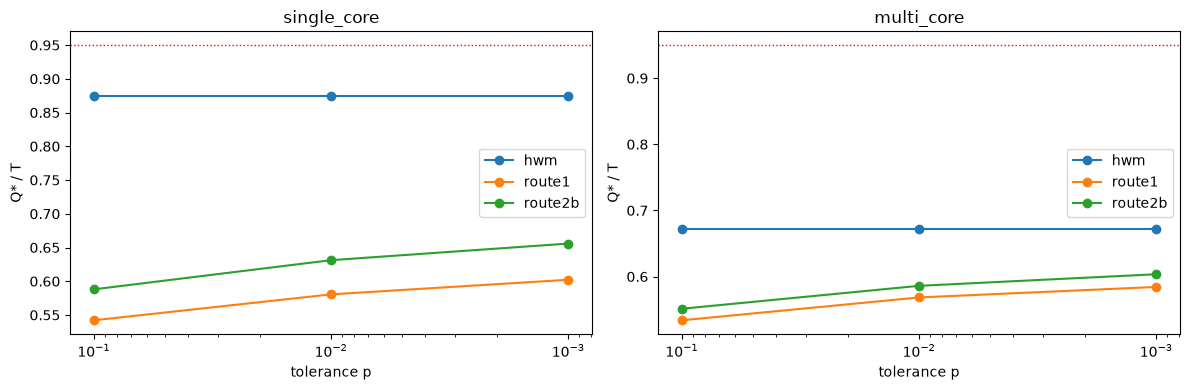

written /home/silvia/Documents/GraduationProject/research-questions/RQ2/analysis_procedure3/budgets/budgets_workload4_iter0.csv


In [12]:
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(6 * len(SCENARIOS), 4), squeeze=False)
for ax, scen in zip(axes[0], SCENARIOS):
    for route, g in bud[bud.scenario == scen].groupby("route"):
        ax.plot(g.p, g.Q_over_T, "o-", label=route)
    ax.axhline(ADMISSION_MAX, color="red", ls=":", lw=1); ax.set_xscale("log"); ax.invert_xaxis()
    ax.set_title(scen); ax.set_xlabel("tolerance p"); ax.set_ylabel("Q* / T"); ax.legend()
plt.tight_layout(); plt.show()

# file for the validation driver: same format as validation/budgets.csv (Route 3 is one row, p = "all")
def export_budgets(table, path):
    OUT_DIR.mkdir(exist_ok=True)
    exp = table[(table.route != "hwm") | (table.p == HWM_P)].copy()
    exp["p"] = [("all" if r == "hwm" else p) for r, p in zip(exp.route, exp.p)]
    exp["runtime_us"] = (exp.Q_ms * 1000).round().astype(int); exp["period_us"] = round(PERIOD_MS * 1000)
    exp[["scenario", "route", "p", "Q_ms", "Q_over_T", "runtime_us", "period_us", "admitted"]].to_csv(path, index=False)

export_budgets(bud, BUDGETS_FILE)
print("written", BUDGETS_FILE)

### 5.4 The window requirement (m,k) and the budget of a level

The tolerance $p$ bounds how **often** a job exceeds its budget. An application can also need a **window requirement**, the **(m,k) constraint**: in any $k$ consecutive jobs **at least $m$ meet their deadline** (so at most $k-m$ miss). Overruns that come in bursts break it even when $P(C>Q)\le p$.
It needs its own tolerance: "at least $m$ of any $k$ deadlines met, always" cannot be guaranteed statistically. The share of sliding windows of $k$ jobs that violate it is at most $\varepsilon$ (`EPS_MK`). A **level** pairs a rate tolerance with a window requirement (see `LEVELS` in the configuration).

**Step 1: how many overruns a window tolerates.** Under a hard CBS reservation with the skip policy an overrun costs about **two** misses (the late job and the skipped activation), so a window tolerates $j=\lfloor (k-m)/2\rfloor$ overruns: (23,24) has $j=0$ (no overrun in any window), (8,10) has $j=1$.

**Step 2: $C_{(m,k)}$ from the measured traces, like $C_p$.** For a candidate level $c$ count the windows of $k$ consecutive jobs holding **more than $j$ jobs with $C+\delta>c$**. $C_{(m,k)}$ is the smallest $c$ for which that share of windows is at most $\varepsilon$. Counting on the real traces keeps the clustering of slow jobs. $C_p$ is a bound of the same quantity $C+\delta$.

**Step 3: the same margins for both bounds, one budget.**

| Route | Budget |
|---|---|
| 1 (stress-profiled) | $Q^*=\max\big(C_p^{stress},\,C_{(m,k)}^{stress}\big)\cdot\alpha_{drift}(p)$ |
| 2 (platform factor) | $Q^*=\max\big(C_p^{base},\,C_{(m,k)}^{base}\big)\cdot\alpha_{platform}(m_{enemy})\cdot\alpha_{drift}(p)$ |

The factors are positive, so it does not matter whether they are applied before or after the maximum. Each requirement is a constraint on the budget and both improve as $Q$ grows, so the maximum is the smallest budget meeting both.
$\alpha_{drift}(p)$ is the spread of $C_p$ across the baselines (section 4.1): a level shift of a session or an instance. The spread of $C_{(m,k)}$ across the same baselines is shown as `alpha_mk` but **not used**: in the extreme tail it measures whether a baseline happened to contain an episode, not drift. Episodes enter through the envelope: $C_{(m,k)}$ is the maximum over all profiling runs (episode-inclusive policy).

**What the budget guarantees, and what it does not.** $Q^*$ is about the misses **caused by overruns** (with their skip effect). Stalls and late starts are not controlled by $Q$; they are measured in the online validation and reported separately. A stall longer than the window breaks $(m,k)$ for any budget: that is a statement about the platform.

In [13]:
rows = []
for scen, insts in SCENARIOS.items():
    base_all = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]          # profiling baselines and baselines of the other VMs
    for name, p, (m, k) in LEVELS:
        spread_mk = max((lambda v: max(v) / min(v))([count_budget(series[(n, scen, i)], m, k, EPS_MK) for n in base_all if (n, scen, i) in series]) for i in insts)
        alpha = alpha_drift.loc[(scen, p), "alpha"]; alpha = 1.0 if np.isnan(alpha) else alpha
        for route in ("route1", "route2b"):
            names = prof_runs(scen, "stress" if route == "route1" else "base")
            c_p = max(bnd[(n, scen, i)].loc[p, "ucb"] for n in names for i in insts)
            c_mk = max(count_budget(series[(n, scen, i)], m, k, EPS_MK) for n in names for i in insts)
            fac = alpha * (1.0 if route == "route1" else ALPHA_PLATFORM[M_USED[scen]])
            star = max(c_p, c_mk) * fac
            rows.append(dict(scenario=scen, route=route, level=name, p=p, m=m, k=k, eps=EPS_MK, C_p=c_p, C_mk=c_mk, alpha_drift=alpha, alpha_mk=spread_mk,
                             Q_p_ms=c_p * fac, Q_mk_ms=c_mk * fac, Q_ms=star, extra_over_Q_p=star / (c_p * fac) - 1, dominated_by="(m,k)" if c_mk > c_p else "p",
                             Q_over_T=star / PERIOD_MS, runtime_us=int(round(star * 1000)), period_us=round(PERIOD_MS * 1000), admitted=star / PERIOD_MS <= ADMISSION_MAX))
comb = pd.DataFrame(rows)
display(comb[["scenario", "route", "level", "p", "m", "k", "C_p", "C_mk", "alpha_drift", "alpha_mk", "Q_p_ms", "Q_mk_ms", "Q_ms", "extra_over_Q_p", "dominated_by", "Q_over_T", "admitted"]].set_index(["scenario", "route", "level"]))
print("C_p, C_mk in ms (bounds of C + delta); Q_p = C_p x factors, Q_mk = C_mk x factors, Q* = max;  extra_over_Q_p = what the window requirement costs;  alpha_mk is shown, not used")

p   m   k    C_p   C_mk  alpha_drift  alpha_mk  Q_p_ms  Q_mk_ms   Q_ms  extra_over_Q_p dominated_by  Q_over_T  admitted
scenario    route   level                                                                                                                              
single_core route1  relaxed 0.010  18  20 27.492 28.090        1.056     1.058  29.029   29.661 29.661           0.022        (m,k)     0.593      True
            route2b relaxed 0.010  18  20 26.929 27.528        1.056     1.058  31.562   32.265 32.265           0.022        (m,k)     0.645      True
            route1  strict  0.001  19  20 28.370 28.438        1.061     1.065  30.111   30.184 30.184           0.002        (m,k)     0.604      True
            route2b strict  0.001  19  20 27.833 27.937        1.061     1.065  32.792   32.914 32.914           0.004        (m,k)     0.658      True
multi_core  route1  relaxed 0.010  18  20 26.822 27.343        1.060     1.051  28.422   28.974 28.974           0.019        (m,k)     0.579      True
            route2b relaxed 0.010  18  20 26.086 26.591        1.060     1.051  29.301   29.868 29.868           0.019        (m,k)     0.597      True
            route1  strict  0.001  19  20 27.632 27.682        1.057     1.055  29.216   29.269 29.269           0.002        (m,k)     0.585      True
            route2b strict  0.001  19  20 26.924 26.993        1.057     1.055  30.175   30.252 30.252           0.003        (m,k)     0.605      True

C_p, C_mk in ms (bounds of C + delta); Q_p = C_p x factors, Q_mk = C_mk x factors, Q* = max;  extra_over_Q_p = what the window requirement costs;  alpha_mk is shown, not used


### 5.5 Budgets of the levels to run online

The table is the list of budgets to give to KubeDeadline (Routes 1 and 2; Route 3 is a high-water mark and has no window effect). `P3_FILE` has the columns of the driver (`runtime_us`, `period_us`) plus the level, p, (m,k) and the two components $Q_p$ and $Q_{(m,k)}$.

In [14]:
p3 = comb.sort_values(["scenario", "route", "p"], ascending=[True, True, False]).reset_index(drop=True)
display(p3[["scenario", "route", "level", "p", "m", "k", "Q_p_ms", "Q_mk_ms", "Q_ms", "extra_over_Q_p", "dominated_by", "Q_over_T", "admitted"]].set_index(["scenario", "route", "level"]))
OUT_DIR.mkdir(exist_ok=True)
p3.to_csv(P3_FILE, index=False)
print("written", P3_FILE, "|", len(p3), "budgets,", int(p3.admitted.sum()), "admitted")

p   m   k  Q_p_ms  Q_mk_ms   Q_ms  extra_over_Q_p dominated_by  Q_over_T  admitted
scenario    route   level                                                                                         
multi_core  route1  relaxed 0.010  18  20  28.422   28.974 28.974           0.019        (m,k)     0.579      True
                    strict  0.001  19  20  29.216   29.269 29.269           0.002        (m,k)     0.585      True
            route2b relaxed 0.010  18  20  29.301   29.868 29.868           0.019        (m,k)     0.597      True
                    strict  0.001  19  20  30.175   30.252 30.252           0.003        (m,k)     0.605      True
single_core route1  relaxed 0.010  18  20  29.029   29.661 29.661           0.022        (m,k)     0.593      True
                    strict  0.001  19  20  30.111   30.184 30.184           0.002        (m,k)     0.604      True
            route2b relaxed 0.010  18  20  31.562   32.265 32.265           0.022        (m,k)     0.645      True
                    strict  0.001  19  20  32.792   32.914 32.914           0.004        (m,k)     0.658      True

written /home/silvia/Documents/GraduationProject/research-questions/RQ2/analysis_procedure3/budgets/budgets_workload4_p3_iter0.csv | 8 budgets, 8 admitted


## 6. Offline validation on held-out data

A budget is **valid on a held-out run** if its overrun probability $P(C>Q)$ is at most p, judged with the upper confidence bound of `exceed_test`:
overruns closer than `GAP_JOBS` jobs form one cluster, $P_{ucb} = CP_{upper}(\#clusters, N)\cdot(\text{mean cluster size})$, pass if $P_{ucb}\le p$.

- **6.1 Held-out baselines (leave one run out).** For each baseline run h except the reference (`baseline1`): $\alpha_{drift}$ from the **other** runs, $Q = C_p(\text{reference})\cdot\alpha_{drift}^{(-h)}$, applied to h. Tests whether the spread rule predicts a new run.
- **6.2 Held-out stressed runs.** The stressed runs on the other VMs are not used by any factor. The budgets of section 5 (Route 1 and 2) are applied to them.

In [15]:
ref = "profiling_baseline1"
rows = []
for scen, insts in SCENARIOS.items():
    names = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]
    for h in names:
        if h == ref:
            continue
        for inst in insts:
            for p in P_LIST:
                c_ref = bnd[(ref, scen, inst)].loc[p, "ucb"]
                v = np.array([bnd[(n, scen, inst)].loc[p, "ucb"] for n in names if n != h])
                Q = c_ref * v.max() / v.min()                                   # before: spread of the OTHER runs
                rate, ncl, ucb, ok = exceed_test(series[(h, scen, inst)], Q, p)
                Q1 = max(Q, c_ref * alpha_drift.loc[(scen, p), "alpha"])        # after: alpha_drift of 4.1 (all runs, h included)
                rate1, ncl1, ucb1, ok1 = exceed_test(series[(h, scen, inst)], Q1, p)
                rows.append(dict(scenario=scen, held_out=h, instance=inst, p=p, Q_ms=Q, overrun_rate=rate, clusters=ncl, P_ucb=ucb, passed=ok,
                                 Q1_ms=Q1, overrun_rate1=rate1, clusters1=ncl1, P_ucb1=ucb1, passed1=ok1))
loo = pd.DataFrame(rows)
display(loo.set_index(["scenario", "held_out", "instance", "p"]))
print(loo.groupby(["scenario", "p"]).agg(tests=("passed", "size"), passed_before=("passed", "sum"), passed_after=("passed1", "sum")).to_string())
print("\n'after' uses alpha_drift WITH the held-out run: a consistency check, not an independent validation (see 6.3).")

Q_ms  overrun_rate  clusters  P_ucb  passed  Q1_ms  overrun_rate1  clusters1  P_ucb1  passed1
scenario    held_out               instance  p                                                                                                    
single_core profiling_baseline2    instance0 0.100 26.488         0.011        76  0.014    True 26.488          0.011         76   0.014     True
                                             0.010 28.434         0.000         0  0.000    True 28.434          0.000          0   0.000     True
                                             0.001 29.542         0.000         0  0.000    True 29.542          0.000          0   0.000     True
            drift_worker7_baseline instance0 0.100 25.469         0.010        34  0.013    True 26.488          0.000          2   0.000     True
                                             0.010 27.271         0.000         0  0.000    True 28.434          0.000          0   0.000     True
                                             0.001 28.317         0.000         0  0.000    True 29.542          0.000          0   0.000     True
multi_core  profiling_baseline2    instance0 0.100 25.093         0.011        50  0.015    True 25.997          0.002         43   0.003     True
                                             0.010 26.769         0.000         1  0.000    True 27.642          0.000          0   0.000     True
                                             0.001 27.787         0.000         0  0.000    True 28.451          0.000          0   0.000     True
                                   instance1 0.100 25.021         0.013        50  0.016    True 26.007          0.002         43   0.003     True
                                             0.010 26.667         0.000         0  0.000    True 27.639          0.000          0   0.000     True
                                             0.001 27.728         0.000         0  0.000    True 28.467          0.000          0   0.000     True
            drift_worker6_baseline instance0 0.100 25.305         0.074        63  0.092    True 25.997          0.034         61   0.041     True
                                             0.010 26.938         0.006        37  0.008    True 27.642          0.001         17   0.001     True
                                             0.001 27.552         0.001        21  0.002   False 28.451          0.000          0   0.000     True
                                   instance1 0.100 25.322         0.067        75  0.082    True 26.007          0.029         59   0.037     True
                                             0.010 26.933         0.005        34  0.007    True 27.639          0.001         15   0.001     True
                                             0.001 27.631         0.001        15  0.001   False 28.467          0.000          0   0.000     True

                   tests  passed_before  passed_after
scenario    p                                        
multi_core  0.001      4              2             4
            0.010      4              4             4
            0.100      4              4             4
single_core 0.001      2              2             2
            0.010      2              2             2
            0.100      2              2             2

'after' uses alpha_drift WITH the held-out run: a consistency check, not an independent validation (see 6.3).


In [16]:
rows = []
for r in runs:
    if not (r["group"] == "drift" and r["kind"] == "stress"):
        continue
    for inst in SCENARIOS[r["scen"]]:
        key = (r["run"], r["scen"], inst)
        if key not in series:
            continue
        for route in ("route1", "route2b"):
            for p in P_LIST:
                Q = bud[(bud.scenario == r["scen"]) & (bud.route == route) & (bud.p == p)].Q_ms.iloc[0]
                rate, ncl, ucb, ok = exceed_test(series[key], Q, p)
                rows.append(dict(scenario=r["scen"], held_out=r["run"], instance=inst, route=route, p=p, Q_ms=Q, overrun_rate=rate, clusters=ncl, P_ucb=ucb, passed=ok))
held = pd.DataFrame(rows)
if len(held):
    display(held.set_index(["scenario", "held_out", "instance", "route", "p"]))
    print(held.groupby(["scenario", "route", "p"]).passed.all().unstack("p").to_string())
else:
    print("no stressed runs on the other VMs")

Q_ms  overrun_rate  clusters  P_ucb  passed
scenario    held_out             instance  route   p                                                  
single_core drift_worker7_cache  instance0 route1  0.100 27.107         0.001        18  0.002    True
                                                   0.010 29.029         0.000         1  0.000    True
                                                   0.001 30.111         0.000         0  0.000    True
                                           route2b 0.100 29.402         0.000         1  0.000    True
                                                   0.010 31.562         0.000         0  0.000    True
                                                   0.001 32.792         0.000         0  0.000    True
            drift_worker7_memory instance0 route1  0.100 27.107         0.000         1  0.000    True
                                                   0.010 29.029         0.000         0  0.000    True
                                                   0.001 30.111         0.000         0  0.000    True
                                           route2b 0.100 29.402         0.000         0  0.000    True
                                                   0.010 31.562         0.000         0  0.000    True
                                                   0.001 32.792         0.000         0  0.000    True
multi_core  drift_worker6_cache  instance0 route1  0.100 26.695         0.019        57  0.024    True
                                                   0.010 28.422         0.001         5  0.002    True
                                                   0.001 29.216         0.001         4  0.002   False
                                           route2b 0.100 27.568         0.004        28  0.005    True
                                                   0.010 29.301         0.001         3  0.002    True
                                                   0.001 30.175         0.001         2  0.002   False
                                 instance1 route1  0.100 26.695         0.017        52  0.022    True
                                                   0.010 28.422         0.001         5  0.002    True
                                                   0.001 29.216         0.001         4  0.002   False
                                           route2b 0.100 27.568         0.003        29  0.004    True
                                                   0.010 29.301         0.001         3  0.002    True
                                                   0.001 30.175         0.001         2  0.002   False
            drift_worker6_memory instance0 route1  0.100 26.695         0.010        44  0.013    True
                                                   0.010 28.422         0.000         2  0.000    True
                                                   0.001 29.216         0.000         2  0.000    True
                                           route2b 0.100 27.568         0.001        18  0.001    True
                                                   0.010 29.301         0.000         2  0.000    True
                                                   0.001 30.175         0.000         2  0.000    True
                                 instance1 route1  0.100 26.695         0.009        44  0.012    True
                                                   0.010 28.422         0.000         2  0.000    True
                                                   0.001 29.216         0.000         2  0.000    True
                                           route2b 0.100 27.568         0.001        14  0.001    True
                                                   0.010 29.301         0.000         2  0.000    True
                                                   0.001 30.175         0.000         2  0.000    True

p                    0.001  0.010  0.100
scenario    route                       
multi_core  route1   False   True   True
            route2b  False   True   True
single_core route1    True   True   True
            route2b   True   True   True


### 6.3 Offline recalibration of the failed baseline tests
Every (held-out run, instance, p) that failed in 6.1 becomes a drift sample:

- $\alpha_{before}$ = the spread **without** that run (the factor that failed in 6.1),
- $\alpha_{after}$ = the spread **with every run** (the value of section 4.1, used by the budgets of section 5),
- $Q_0 = C_p^{ref}\cdot\alpha_{before}$ and $Q_1 = \max(Q_0,\ C_p^{ref}\cdot\alpha_{after})$.

$Q_1$ is already re-tested on the held-out run in the table of 6.1 (`*1` columns), but that run is now part of the calibration, so this is **not** an independent validation: it only shows that the recalibrated value is consistent with the data it contains. The independent offline check of the recalibrated budgets is 6.2 (stressed runs of the other VMs), and the final one is the online run.

In [17]:
fail = loo[~loo.passed]
recal_offline = fail.assign(alpha_before=lambda x: x.Q_ms / [bnd[(ref, r.scenario, r.instance)].loc[r.p, "ucb"] for r in x.itertuples()],
                            alpha_after=lambda x: [alpha_drift.loc[(r.scenario, r.p), "alpha"] for r in x.itertuples()],
                            Q1_over_Q0=lambda x: x.Q1_ms / x.Q_ms)
cols = ["alpha_before", "alpha_after", "Q_ms", "Q1_ms", "Q1_over_Q0", "P_ucb", "P_ucb1", "passed1"]
if len(recal_offline):
    display(recal_offline.set_index(["scenario", "held_out", "instance", "p"])[cols].rename(columns={"Q_ms": "Q0", "Q1_ms": "Q1", "passed1": "passes_after"}))
else:
    print("every held-out baseline test passed: no recalibration needed")

alpha_before  alpha_after     Q0     Q1  Q1_over_Q0  P_ucb  P_ucb1  passes_after
scenario   held_out               instance  p                                                                                      
multi_core drift_worker6_baseline instance0 0.001         1.024        1.057 27.552 28.451       1.033  0.002   0.000          True
                                  instance1 0.001         1.026        1.057 27.631 28.467       1.030  0.001   0.000          True

### If a held-out test fails
An offline failure means the held-out data contain variation the profiling did not. Before changing anything:

1. **Setup:** was the run made under the same conditions (VM type, threads, input, enemy placement)? If not it is not a valid test: exclude it and say why.
2. **Episode:** is the failure confined to a stretch of the run (a stall or burst)? With an *episode-excluded* policy it is reported as an episode with its rate; with *episode-inclusive* it is a failure.
3. **Drift larger than $\alpha_{drift}$** (the usual cause when the distribution is narrow, e.g. the audio workload): $\alpha_{drift}$ came from few runs and the held-out run is a new sample outside the observed spread.

Then recalibrate **once**: the held-out run becomes one more drift sample. Section 4 already uses every baseline run, so the budgets of section 5 are the recalibrated ones; rerun from section 4 after adding the run to `alpha_drift/results/`. Do not iterate offline repeatedly: each round uses up a held-out set. After that the **online run is the independent test**.

### 6.4 The level budgets on held-out stressed runs

The stressed runs on the other VMs (the same ones as 6.2) are tested with the budgets $Q^*$ of 5.5, each requirement with its own tolerance:
- **rate:** $P_{ucb}(C+\delta>Q^*)\le p$ (`exceed_test`, as in 6.2),
- **window:** the share of windows of $k$ jobs with more than $j=\lfloor(k-m)/2\rfloor$ overruns is at most `EPS_MK`.

No factor of the procedure has seen these runs.

In [18]:
rows = []
for r in runs:
    if not (r["group"] == "drift" and r["kind"] == "stress"):
        continue
    for inst in SCENARIOS[r["scen"]]:
        key = (r["run"], r["scen"], inst)
        if key not in series:
            continue
        for q in p3[p3.scenario == r["scen"]].itertuples():
            rate, ncl, ucb, ok_p = exceed_test(series[key], q.Q_ms, q.p)
            v = window_share(series[key], q.Q_ms, q.m, q.k)
            rows.append(dict(scenario=r["scen"], held_out=r["run"], instance=inst, route=q.route, level=q.level, Q_ms=q.Q_ms, P_ucb=ucb, rate_ok=ok_p, V=v, window_ok=v <= EPS_MK))
held_lv = pd.DataFrame(rows)
if len(held_lv):
    held_lv["passed"] = held_lv.rate_ok & held_lv.window_ok
    print(held_lv.groupby(["scenario", "route", "level"]).agg(runs=("passed", "size"), passed_both=("passed", "sum"), rate_ok=("rate_ok", "sum"), window_ok=("window_ok", "sum"),
                                                          worst_P_ucb=("P_ucb", "max"), worst_V=("V", "max")).to_string())
else:
    print("no stressed runs on the other VMs")

                             runs  passed_both  rate_ok  window_ok  worst_P_ucb  worst_V
scenario    route   level                                                               
multi_core  route1  relaxed     4            4        4          4        0.002    0.002
                    strict      4            2        2          4        0.002    0.003
            route2b relaxed     4            4        4          4        0.002    0.002
                    strict      4            2        2          4        0.002    0.003
single_core route1  relaxed     2            2        2          2        0.000    0.000
                    strict      2            2        2          2        0.000    0.000
            route2b relaxed     2            2        2          2        0.000    0.000
                    strict      2            2        2          2        0.000    0.000


## 7. Online validation under KubeDeadline

The budgets of `ONLINE_DIR/budgets.csv` (what was really run) are given to KubeDeadline and the workload runs under them (without interference and with the memory enemy). The runs are read from `ONLINE_DIR/results/<scenario>/<route>/<level>_<none|memory>/instance*.csv`. If the folder does not exist yet the section prints a message.

Each run is judged against its level with the two requirements:

| Verdict | Rule |
|---|---|
| **rate** | $P_{ucb}(C+\delta>Q)\le p$ (cluster-aware bound of `exceed_test`): **pass**. Observed rate $\le p$ but the bound above it: **inconclusive** (too few jobs for the confidence limit; at $p=10^{-3}$ the runs have $N\cdot p=20$-$50$). Observed rate $>p$: **fail** |
| **window** | share of sliding windows of $k$ jobs with more than $k-m$ misses, counting only the misses of bursts that contain an overrun (`V_overrun`, what the budget controls): $\le\varepsilon$ is **pass** |

`V_total` also counts the stalls and late starts, `V_other` only those, `stalls` is the number of platform stalls (W above `STALL_FRAC`$\cdot T$ without a miss before): they are **reported, not budgeted**. A **cell** (scenario, route, level) passes when every run of it passes both verdicts.

In [19]:
rows, val_c = [], {}
if (ONLINE_DIR / "budgets.csv").exists() and (ONLINE_DIR / "results").exists():
    for _, b in pd.read_csv(ONLINE_DIR / "budgets.csv").iterrows():
        Q = b.runtime_us / 1000
        for interf in INTERFERENCES:
            d = ONLINE_DIR / "results" / b.scenario / b.route / f"{b.level}_{interf}"
            for inst in SCENARIOS[b.scenario]:
                if not (d / f"{inst}.csv").exists():
                    continue
                df = read_run(d / f"{inst}.csv")
                c = (df[df.skipped == 0].cpu_ns / 1e6).to_numpy()
                bad = ((df.skipped == 1) | (df.deadline_met == 0)).to_numpy()
                over = overrun_misses(bad, ((df.cpu_ns / 1e6) + DELTA_MS > Q).to_numpy())
                rate, ncl, ucb, ok = exceed_test(c, Q, b.p)
                v_over, v_tot, v_oth = (violation_fraction(x, b.m, b.k) for x in (over, bad, bad & ~over))
                rows.append(dict(scenario=b.scenario, route=b.route, level=b.level, interference=interf, instance=inst, Q_ms=Q, N=len(c), overruns=int((c + DELTA_MS > Q).sum()),
                                 P_over=rate, P_ucb=ucb, p=b.p, rate_verdict="pass" if ok else ("inconclusive" if rate <= b.p else "fail"),
                                 V_overrun=v_over, V_total=v_tot, V_other=v_oth, window_verdict="pass" if v_over <= EPS_MK else "fail",
                                 misses=int(bad.sum()), stalls=stall_count((df.wait_ns / 1e6).to_numpy(), bad)))
                val_c.setdefault((b.scenario, b.route, b.level), []).append(c)
online = pd.DataFrame(rows)
if len(online):
    display(online.set_index(["scenario", "route", "level", "interference", "instance"]))
else:
    print("no online results yet in", ONLINE_DIR)

no online results yet in /home/silvia/Documents/GraduationProject/research-questions/RQ2/workload4/validation_p4/iter0


In [20]:
if len(online):
    key = ["scenario", "route", "level"]
    online_cells = online.groupby(key).agg(runs=("N", "size"), rate_fail=("rate_verdict", lambda s: (s == "fail").sum()), rate_inconclusive=("rate_verdict", lambda s: (s == "inconclusive").sum()),
                                           window_fail=("window_verdict", lambda s: (s == "fail").sum()), worst_P_over=("P_over", "max"), worst_V_overrun=("V_overrun", "max"),
                                           worst_V_total=("V_total", "max"), stalls=("stalls", "sum"), Q_ms=("Q_ms", "first"))
    online_cells["status"] = np.select([(online_cells.rate_fail > 0) & (online_cells.window_fail > 0), online_cells.rate_fail > 0, online_cells.window_fail > 0, online_cells.rate_inconclusive > 0],
                                       ["FAIL rate and window", "FAIL rate", "FAIL window", "pass (rate inconclusive)"], "pass")
    display(online_cells)
    print(online_cells.status.value_counts().to_string())
    print("\nby interference (runs x instance):")
    print(online.groupby(["level", "interference"]).agg(runs=("N", "size"), rate_pass=("rate_verdict", lambda s: (s == "pass").sum()), rate_inconclusive=("rate_verdict", lambda s: (s == "inconclusive").sum()),
                                                      rate_fail=("rate_verdict", lambda s: (s == "fail").sum()), window_pass=("window_verdict", lambda s: (s == "pass").sum())).to_string())

## 8. Recalibration (if the practitioner wants)

A cell that **fails** online (rate or window; an inconclusive rate does not trigger it) is recalibrated with the **same estimators on the validation data**: $C_p^{val}$ and $C_{(m,k)}^{val}$ of the C series of the cell's runs (the worst run of the cell, every instance and interference), and

$$Q_1=\max\big(Q_0,\ \max(C_p^{val},C_{(m,k)}^{val})\cdot\alpha_{drift}\big)$$

$\alpha_{drift}$ is kept because future deployments can drift again; the platform factor is not applied, the validation data were measured on the platform itself.
- **Stop rule:** at most `K_MAX` recalibrations; each one must be validated on a **fresh** run (copy the next file to `validation_p3/iter<ITER+1>/budgets.csv`, regenerate the pods, rerun only the changed cells, set `ITER = ITER + 1`). After the last one the cell falls back to Route 3; if Route 3 also fails, the requirement is **not achievable** on this platform. Budgets above `ADMISSION_MAX` are not admitted.
- Misses with $C+\delta\le Q$ (stalls, late starts) do not trigger it: a bigger budget does not remove them.
- Skipped jobs have no C, so a far-too-small budget makes $C^{val}$ an underestimate; a second round corrects it.

In [21]:
if len(online) == 0:
    print("nothing to recalibrate: no online results")
else:
    rows, new = [], p3.copy()
    new["action"] = "keep"
    for r in online_cells.reset_index().itertuples():                     # the budgets that were run are the starting point
        sel = (new.scenario == r.scenario) & (new.route == r.route) & (new.level == r.level)
        new.loc[sel, ["Q_ms", "Q_over_T", "runtime_us"]] = [r.Q_ms, r.Q_ms / PERIOD_MS, int(round(r.Q_ms * 1000))]
    for idx, r in online_cells[online_cells.status.str.startswith("FAIL")].reset_index().iterrows():
        sel = (new.scenario == r.scenario) & (new.route == r.route) & (new.level == r.level)
        cur = new[sel].iloc[0]
        c_val = []
        for c in val_c[(r.scenario, r.route, r.level)]:
            c_val.append(max(bound_table(c + DELTA_MS, [cur.p]).loc[cur.p, "ucb"], count_budget(c, cur.m, cur.k, EPS_MK)))
        c_hat = np.nan if np.isnan(c_val).all() else np.nanmax(c_val)
        q1 = max(r.Q_ms, c_hat * cur.alpha_drift) if not np.isnan(c_hat) else np.nan
        if np.isnan(q1):
            action = "no estimate (N*p < NP_MIN): collect more validation jobs"
        elif ITER + 1 > K_MAX:
            q1 = bud[(bud.scenario == r.scenario) & (bud.route == "hwm")].Q_ms.iloc[0]; action = "limit reached: fall back to Route 3"
        elif q1 / PERIOD_MS > ADMISSION_MAX:
            action = "not admitted: Q1/T above the limit"
        else:
            action = "recalibrate"
        if action in ("recalibrate", "limit reached: fall back to Route 3"):
            new.loc[sel, ["Q_ms", "Q_over_T", "runtime_us", "admitted", "action"]] = [q1, q1 / PERIOD_MS, int(round(q1 * 1000)), q1 / PERIOD_MS <= ADMISSION_MAX, action]
        rows.append(dict(scenario=r.scenario, route=r.route, level=r.level, status=r.status, Q0=r.Q_ms, C_val=c_hat, alpha_drift=cur.alpha_drift, Q1=q1, Q1_over_Q0=q1 / r.Q_ms, Q1_over_T=q1 / PERIOD_MS, action=action))
    if rows:
        display(pd.DataFrame(rows).set_index(["scenario", "route", "level"]))
        new.to_csv(P3_NEXT, index=False)
        print("written", P3_NEXT, "-> validate the changed cells on fresh runs (ITER =", ITER + 1, ")")
    else:
        print("every cell passed: nothing to recalibrate")

nothing to recalibrate: no online results


## 9. What to report for this workload

- Section 1-2: C, R, W statistics and which tolerances the empirical bound supports ($N\cdot p\ge10$).
- Section 4: $\alpha_{drift}$ with n runs and the coverage $n/(n+1)$, $\alpha_{cores}$.
- Section 5: $Q_p$ for the three routes, and per level $C_p$, $C_{(m,k)}$, $Q^*$, which requirement dominates and the extra budget the window requirement costs. `alpha_mk` as a finding: in the extreme tail the baselines differ because of episodes.
- Section 6: offline held-out result (and the cause of any failure).
- Section 7: per cell the rate verdict and the window verdict, with the stalls reported separately.
- Section 8: cells recalibrated, iterations needed and the budget growth $Q_1/Q_0$.